In [43]:
import requests
import pandas as pd

In [6]:
url = "https://api.open-meteo.com/v1/forecast"
params = {
	"latitude": "tromsø",
	"longitude": -0.1257,
	"hourly": "temperature_2m",
	"timezone": "Europe/Berlin",
	"start_date": "2026-11-02",
	"end_date": "2026-11-09",
}

In [7]:
response = requests.get(url, params=params)
response.raise_for_status()  # Raises an error if the request failed
# data = response.json()

HTTPError: 503 Server Error: Service Unavailable for url: https://api.open-meteo.com/v1/forecast?latitude=troms%C3%B8&longitude=-0.1257&hourly=temperature_2m&timezone=Europe%2FBerlin&start_date=2026-11-02&end_date=2026-11-09

In [26]:
weather = pd.DataFrame({
    "time": data["hourly"]["time"],
    "temperature_2m": data["hourly"]["temperature_2m"],
})

In [25]:
import requests

url = "https://api.met.no/weatherapi/locationforecast/2.0/compact"

params = {
    "lat": 59.91,
    "lon": 10.75,
}

headers = {
    "User-Agent": "jaimes-weather-app/1.0 j.mccutcheon@uit.no"
}

response = requests.get(url, params=params, headers=headers, timeout=10)
response.raise_for_status()

forecast_tromso = response.json()

# cvhange for london
params = {
    "lat": 51.91,
    "lon": 0.75,
}

response = requests.get(url, params=params, headers=headers, timeout=10)
response.raise_for_status()

forecast_london = response.json()


In [8]:
forecast.keys()

dict_keys(['type', 'geometry', 'properties'])

In [13]:
forecast['properties'].keys()

dict_keys(['meta', 'timeseries'])

In [26]:
ts_tromso = forecast_tromso['properties']['timeseries']
ts_london = forecast_london['properties']['timeseries']

In [27]:
temps_tromso = []

for t in ts_tromso:
    print(t['time'], t['data']['instant']['details']['air_temperature'])
    temps_tromso.append(t['data']['instant']['details']['air_temperature'])


temps_london = []

for t in ts_london:
    print(t['time'], t['data']['instant']['details']['air_temperature'])
    temps_london.append(t['data']['instant']['details']['air_temperature'])


2026-11-02T14:00:00Z 9.8
2026-11-02T15:00:00Z 8.6
2026-11-02T16:00:00Z 6.8
2026-11-02T17:00:00Z 5.3
2026-11-02T18:00:00Z 4.3
2026-11-02T19:00:00Z 3.9
2026-11-02T20:00:00Z 3.5
2026-11-02T21:00:00Z 3.3
2026-11-02T22:00:00Z 3.2
2026-11-02T23:00:00Z 3.2
2026-11-03T00:00:00Z 3.3
2026-11-03T01:00:00Z 3.3
2026-11-03T02:00:00Z 3.3
2026-11-03T03:00:00Z 3.3
2026-11-03T04:00:00Z 3.4
2026-11-03T05:00:00Z 3.4
2026-11-03T06:00:00Z 3.5
2026-11-03T07:00:00Z 3.3
2026-11-03T08:00:00Z 3.6
2026-11-03T09:00:00Z 4.7
2026-11-03T10:00:00Z 5.4
2026-11-03T11:00:00Z 6.2
2026-11-03T12:00:00Z 7.0
2026-11-03T13:00:00Z 7.8
2026-11-03T14:00:00Z 8.1
2026-11-03T15:00:00Z 7.5
2026-11-03T16:00:00Z 6.4
2026-11-03T17:00:00Z 5.8
2026-11-03T18:00:00Z 5.3
2026-11-03T19:00:00Z 5.1
2026-11-03T20:00:00Z 4.9
2026-11-03T21:00:00Z 4.8
2026-11-03T22:00:00Z 4.6
2026-11-03T23:00:00Z 4.6
2026-11-04T00:00:00Z 4.5
2026-11-04T01:00:00Z 4.3
2026-11-04T02:00:00Z 4.1
2026-11-04T03:00:00Z 3.8
2026-11-04T04:00:00Z 3.5
2026-11-04T05:00:00Z 3.3


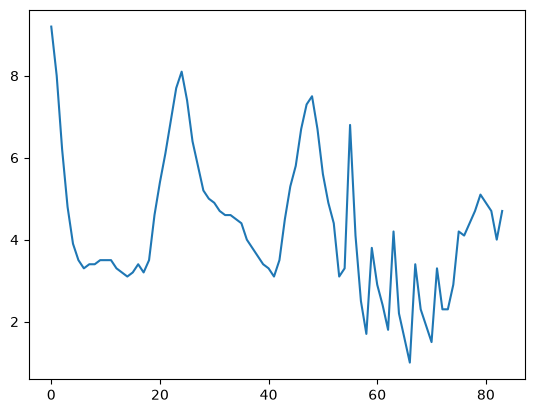

In [24]:
import matplotlib.pyplot as plt

plt.plot(temps)